In [1]:
from math import ceil

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.stats import binom

from shared import set_custom_style

# Set custom plot style
set_custom_style()

['#5842ff', '#ff4000', '#00b368']

The HS proc distribution is just the Repertoire proc distribution, but in groups of 2.

In [2]:
n = 15
hs_pmf = {x: 0 for x in range(ceil(n / 2) + 1)}


def p_hs(k_hs, n_r):
    return sum(
        [binom(n_r, 0.8).pmf(j) for j in range(max(0, 2 * k_hs - 1), 2 * k_hs + 1)]
    )


for k in hs_pmf.keys():
    hs_pmf[k] = p_hs(k, n)

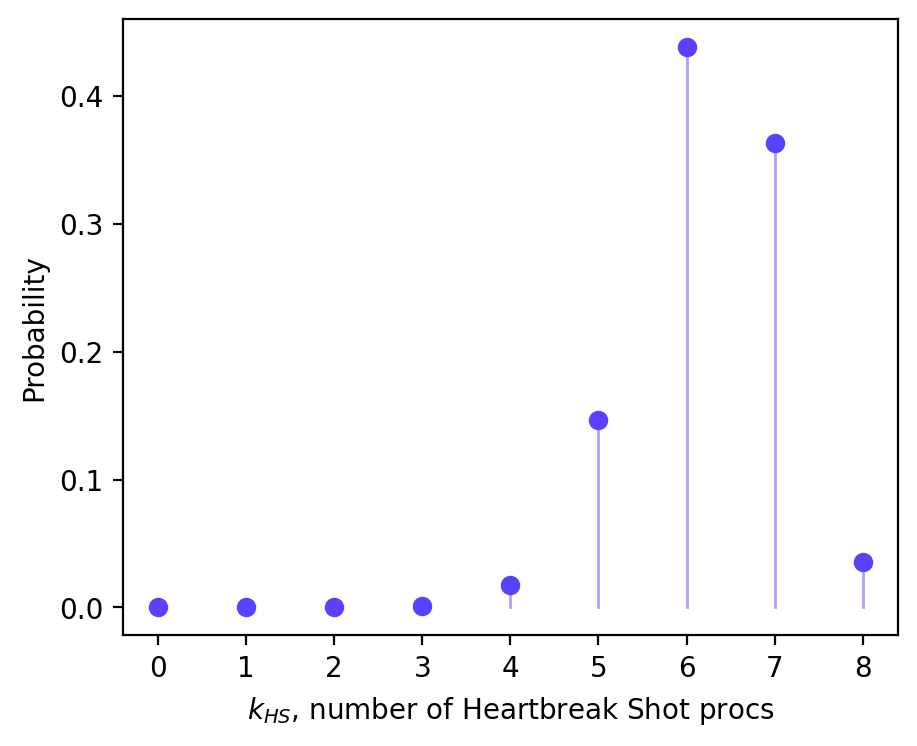

In [3]:
fig, ax = plt.subplots(1, 1, figsize=(5, 4), dpi=200)

ax.scatter(hs_pmf.keys(), hs_pmf.values())
for k, p_val in hs_pmf.items():
    ax.plot([k, k], [0, p_val], color="C0", alpha=0.5, linewidth=1)
ax.set_xlabel(r"$k_{HS}$, number of Heartbreak Shot procs")
ax.set_ylabel("Probability")
plt.savefig("../tex/img/hs-proc-distribution.png")
plt.show()

In [4]:
import pandas as pd
from ffxiv_stats import Rotation

from shared import (
    BARD_RATE,
    mixture_distribution,
    pmf_std,
    relative_d2,
    thousands_formatter,
)

d2 = relative_d2(180)


def make_hs_record(n, p):
    return {
        "n": n,
        "d2": d2,
        "action_name": "Heartbreak Shot",
        "base_action": "Heartbreak Shot",
        "p_n": p[0],
        "p_c": p[1],
        "p_d": p[2],
        "p_cd": p[3],
        "l_c": BARD_RATE.l_c,
        "buffs": 1.01,
        "is_dot": False,
    }


rotation_list = []
# Omit no procs because it messes with things
# It's probability is so small it doesn't matter anyways.
for k in range(1, 9):
    rotation_df = pd.DataFrame([make_hs_record(k, BARD_RATE.p)])
    rotation_list.append(Rotation(rotation_df, 1, 1, 1, 1))

sigma percent change: 69.4%


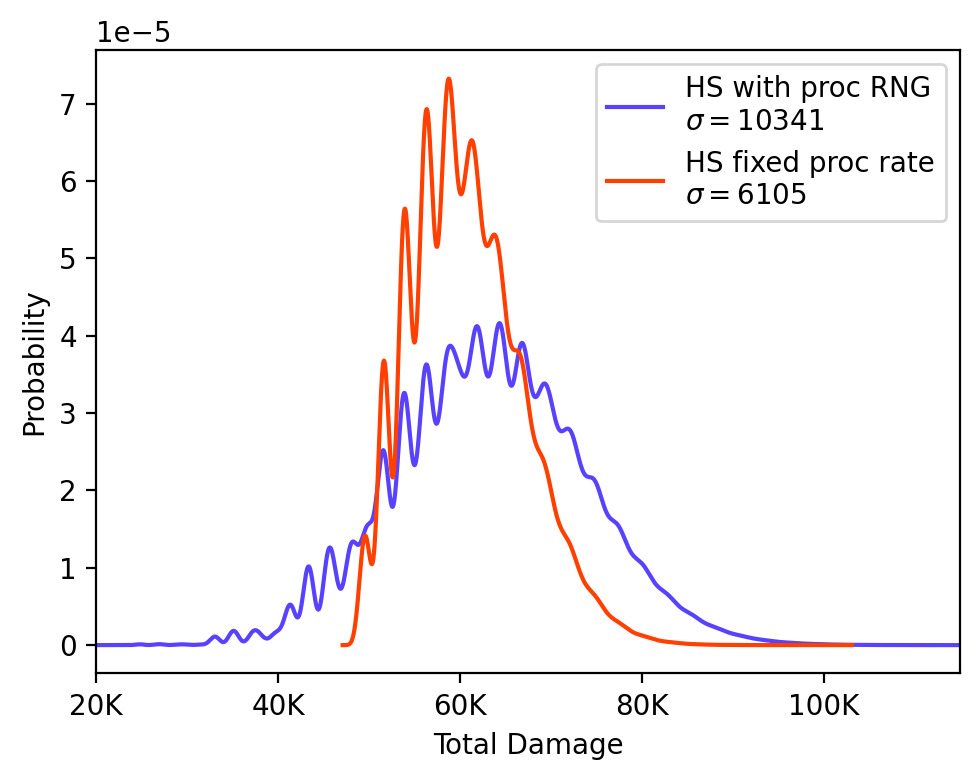

In [5]:
w = list(hs_pmf.values())[1:]
pmf, support = mixture_distribution(rotation_list, w)

mode_pmf = rotation_list[5].rotation_dps_distribution
mode_support = rotation_list[5].rotation_dps_support
mode_std = rotation_list[5].rotation_std

# There is a closed form solution for mixture distribution variance based off weights,
# but it's complicated and I'm lazy
proc_std = pmf_std(support, pmf)

print(f"sigma percent change: {(proc_std - mode_std) / mode_std:.1%}")

fig, ax = plt.subplots(1, 1, figsize=(5, 4), dpi=200)
ax.plot(support, pmf, label="HS with proc RNG\n" + rf"$\sigma={proc_std:.0f}$")
ax.plot(
    mode_support, mode_pmf, label="HS fixed proc rate\n" + rf"$\sigma={mode_std:.0f}$"
)
ax.legend()
ax.xaxis.set_major_formatter(FuncFormatter(thousands_formatter))
ax.set_xlabel("Total Damage")
ax.set_ylabel("Probability")
ax.set_xlim([20000, 115000])
plt.tight_layout()
plt.savefig("../tex/img/hs-dmg-distribution.png")
plt.show()